# XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH DỰ ĐOÁN CUSTOMER CHURN



# 1. Giới thiệu

Notebook này thực hiện xây dựng, đánh giá và tối ưu các mô hình Machine Learning
nhằm dự đoán khả năng khách hàng rời bỏ dịch vụ (**Customer Churn**).

Ba thuật toán được sử dụng gồm:

- **K-Nearest Neighbors (KNN)**
- **Decision Tree (DT)**
- **Naive Bayes (NB)**

### Mục tiêu

- Xây dựng mô hình baseline cho từng thuật toán.
- Đánh giá hiệu quả mô hình bằng các chỉ số phù hợp.
- Tối ưu siêu tham số nhằm cải thiện hiệu suất dự đoán.
- So sánh mô hình trước và sau khi tối ưu.
- So sánh ba thuật toán và lựa chọn mô hình phù hợp cho bài toán Customer Churn.

### Quy trình thực hiện

**Dữ liệu đã tiền xử lý → Baseline → Đánh giá → Tối ưu → Đánh giá lại → So sánh mô hình**

# 2. Khởi tạo môi trường


Import các thư viện cần thiết cho quá trình xây dựng, đánh giá,
tối ưu và trực quan hóa các mô hình Machine Learning.

In [55]:
# Xử lý dữ liệu
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Trực quan hóa
import matplotlib.pyplot as plt

# Models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

# Model selection
from sklearn.model_selection import (
    StratifiedKFold, 
    cross_validate,
    GridSearchCV,
    train_test_split
)

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 3. Chuẩn bị dữ liệu cho Modeling


Dữ liệu sử dụng trong notebook này được kế thừa từ bước
Data Understanding & Preprocessing của nhóm.

Ở bước trước, dữ liệu đã được:

- Làm sạch và xử lý missing values.
- Chia thành tập train/test bằng stratified sampling.
- Chuẩn hóa các biến số.
- One-Hot Encoding các biến phân loại.
- Fit preprocessing trên tập train và transform tập test.

Notebook này sử dụng trực tiếp các tập dữ liệu đã tiền xử lý
để đảm bảo toàn bộ các mô hình được huấn luyện và đánh giá
trên cùng một dữ liệu.

In [2]:
DATA_DIR = Path("../data")

X_train = np.load(DATA_DIR / "X_train_processed.npy")
X_test = np.load(DATA_DIR / "X_test_processed.npy")

y_train = pd.read_csv(
    DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    DATA_DIR / "y_test.csv"
).squeeze("columns")

feature_names = joblib.load(
    DATA_DIR / "feature_names.pkl"
)

class_weight = joblib.load(
    DATA_DIR / "class_weight.pkl"
)

In [3]:
print(f"Kích thước dữ liệu")

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("Number of features:", len(feature_names))

Kích thước dữ liệu
X_train: (5634, 40)
X_test : (1409, 40)
y_train: (5634,)
y_test : (1409,)
Number of features: 40


### Nhận xét

Dữ liệu sau tiền xử lý gồm **40 đặc trưng** và được chia thành
**5.634 mẫu huấn luyện** và **1.409 mẫu kiểm thử**.

Phân bố nhãn cho thấy số khách hàng không Churn lớn hơn số khách hàng Churn.
Do đó, ngoài Accuracy, các chỉ số **Precision, Recall và F1-score**
cần được xem xét khi đánh giá mô hình.

In [4]:
assert X_train.shape[0] == y_train.shape[0]
assert X_test.shape[0] == y_test.shape[0]
assert X_train.shape[1] == len(feature_names)

print("Shape alignment OK")

Shape alignment OK


In [5]:
# y_train = y_train.squeeze()
# y_test = y_test.squeeze()

# print("y_train shape:", y_train.shape)
# print("y_test shape :", y_test.shape)

In [6]:
print("Train labels:", y_train.unique())
print("Test labels :", y_test.unique())

Train labels: [0 1]
Test labels : [0 1]


In [7]:
print("TRAIN")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTEST")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

TRAIN
Churn
0    4139
1    1495
Name: count, dtype: int64
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

TEST
Churn
0    1035
1     374
Name: count, dtype: int64
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [8]:
print("NaN train:", np.isnan(X_train).sum())
print("NaN test :", np.isnan(X_test).sum())

print("Inf train:", np.isinf(X_train).sum())
print("Inf test :", np.isinf(X_test).sum())

NaN train: 0
NaN test : 0
Inf train: 0
Inf test : 0


# 4. Các hàm đánh giá dùng chung


Để đảm bảo các mô hình được đánh giá theo cùng một quy trình,
các hàm đánh giá được định nghĩa một lần và tái sử dụng cho KNN,
Decision Tree và Naive Bayes.

Các chỉ số chính gồm:

- **Accuracy:** tỷ lệ dự đoán đúng trên toàn bộ dữ liệu.
- **Precision:** mức độ chính xác của các dự đoán Churn.
- **Recall:** khả năng phát hiện khách hàng thực sự Churn.
- **F1-score:** cân bằng giữa Precision và Recall.
- **Confusion Matrix:** thể hiện số lượng TN, FP, FN và TP.

In [70]:
def evaluate_model(y_true, y_pred, y_prob, model_name="Model"):
    # Tính các metrics
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    # In metrics
    print(f"===== {model_name} =====")
    print(f"Accuracy : {results['Accuracy']:.4f}")
    print(f"Precision: {results['Precision']:.4f}")
    print(f"Recall   : {results['Recall']:.4f}")
    print(f"F1-score : {results['F1-score']:.4f}")
    print(f"ROC-AUC  : {results['ROC-AUC']:.4f}")

    # Classification Report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    print("Confusion Matrix:")
    print(cm)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Churn", "Churn"]
    )

    display.plot()
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    return results


def compare_model_metrics(baseline_result, tuned_result):
    metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

    comparison_table = pd.DataFrame({
        "Baseline": [baseline_result[m] for m in metrics],
        "Tuned": [tuned_result[m] for m in metrics]
    }, index=metrics)

    comparison_table["Improvement"] = (
        comparison_table["Tuned"] - comparison_table["Baseline"]
    )

    return comparison_table.round(4)

def compare_confusion_matrix(y_test, y_pred_baseline, y_pred_tuned):
    cm_baseline = confusion_matrix(y_test, y_pred_baseline)
    cm_tuned = confusion_matrix(y_test, y_pred_tuned)

    tn_b, fp_b, fn_b, tp_b = cm_baseline.ravel()
    tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()

    cm_comparison = pd.DataFrame({
        "Baseline": [tn_b, fp_b, fn_b, tp_b],
        "Tuned": [tn_t, fp_t, fn_t, tp_t]
    }, index=["TN", "FP", "FN", "TP"])

    cm_comparison["Change"] = (
        cm_comparison["Tuned"] - cm_comparison["Baseline"]
    )

    return cm_comparison


def classify_prediction(y_true, y_pred):
    if y_true == 1 and y_pred == 1:
        return "TP"
    elif y_true == 0 and y_pred == 0:
        return "TN"
    elif y_true == 0 and y_pred == 1:
        return "FP"
    else:
        return "FN"
    
    
def threshold_analysis(
    y_true,
    probabilities,
    cost_fn=5,
    cost_fp=1
):
    results = []

    thresholds = np.arange(0.10, 0.91, 0.05)

    for threshold in thresholds:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        total_cost = (
            fn * cost_fn +
            fp * cost_fp
        )

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "Total Cost": total_cost
        })

    return pd.DataFrame(results)

#  5. K-Nearest Neighbors



## 5.1 Tổng quan

KNN = K_nearest neighbors, k láng giềng gần nhất

Ý tưởng: muốn dự đoán một khách hàng có churn không? -> tìm những khách hàng trong tập train giống người "này" nhất -> xem đa số họ có churn 0 ?  
Ví dụ: K = 5, A = churn, B = churn, C = k churn, D = churn, E = k churn -> 3 churn, 2 k churn ==> predict churn


Khách hàng mới
      ↓
① Tính khoảng cách với khách trong train
      ↓
② Tìm K người gần nhất
      ↓
③ Xem họ thuộc class 0 hay 1
      ↓
④ Majority vote
      ↓
Dự đoán Churn / No Churn

### 5.2 KNN Baseline

In [10]:
knn_baseline = KNeighborsClassifier(n_neighbors=5) # tao model voi k = 5
knn_baseline.fit(X_train, y_train); # train

In [11]:
y_predict_knn_baseline = knn_baseline.predict(X_test) # predict 
y_proba_km = knn_baseline.predict_proba(X_test)[:,1]

Đánh giá KNN baseline 
| Metric    | Câu hỏi nó trả lời                                          |
| --------- | ----------------------------------------------------------- |
| Accuracy  | Tổng thể model đoán đúng bao nhiêu %?                       |
| Precision | Những người model báo churn, bao nhiêu người thực sự churn? |
| Recall    | Những người thực sự churn, model bắt được bao nhiêu?        |
| F1-score  | Cân bằng Precision và Recall                                |
| ROC-AUC   | Model phân biệt churn và non-churn tốt đến đâu?             |

0.5  → gần như random
0.6  → yếu
0.7  → khá
0.8  → tốt
0.9+ → rất tốt
1.0  → hoàn hảo

## 5.3 Đánh giá Baseline

===== KNN Baseline =====
Accuracy : 0.7551
Precision: 0.5397
Recall   : 0.5267
F1-score : 0.5332
ROC-AUC  : 0.7821

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83      1035
           1       0.54      0.53      0.53       374

    accuracy                           0.76      1409
   macro avg       0.69      0.68      0.68      1409
weighted avg       0.75      0.76      0.75      1409

Confusion Matrix:
[[867 168]
 [177 197]]


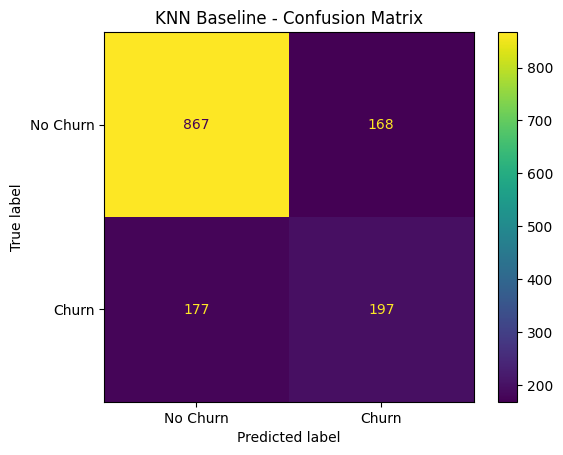

In [12]:
knn_baseline_result = evaluate_model( # danh gia mo hinh 
  y_test, 
  y_predict_knn_baseline, 
  y_proba_km, 
"KNN Baseline") 

1. trong 100 khách -> model dự đoán trúnga 76 khách
2. model cảnh báo 100 khách -> 54 churn thực sự
3. 100 người churn -> model phát hiện được 53 người
4. 
5. yếu

- **867 TN: khách hàng thực sự không churn → KNN dự đoán đúng không churn.**
- **168 FP: thực tế không churn → nhưng model báo churn.**
- **177 FN: thực tế churn → model lại bảo không churn.**
- **197 TP: thực tế churn → model phát hiện đúng.**

---

>  *Mô hình cơ sở KNN đạt độ chính xác khoảng 75,5% **Accuracy**. Tuy nhiên, hiệu suất trong việc nhận diện khách hàng rời bỏ dịch vụ còn khá hạn chế, với chỉ số **recall** (độ nhạy) đạt khoảng 52,7%. Mô hình xác định đúng 197 khách hàng rời bỏ nhưng lại bỏ sót 177 trường hợp thực tế. Do đó, cần tiếp tục tinh chỉnh các siêu tham số để cải thiện khả năng phát hiện những khách hàng có nguy cơ rời bỏ dịch vụ*

## 5.4 Tối ưu siêu tham số KNN

Hiệu suất của KNN phụ thuộc nhiều vào số lượng láng giềng `k`
(`n_neighbors`). Giá trị `k` quá nhỏ có thể khiến mô hình nhạy với nhiễu,
trong khi giá trị `k` quá lớn có thể làm giảm khả năng phân biệt giữa các lớp.

Trong phần này, **GridSearchCV** được sử dụng để thử nghiệm nhiều giá trị
`n_neighbors` và lựa chọn giá trị tốt nhất thông qua **5-fold cross-validation**.

Do dữ liệu Customer Churn có sự mất cân bằng giữa hai lớp,
**F1-score** được sử dụng làm tiêu chí tối ưu nhằm cân bằng giữa
Precision và Recall.

| 5W1H       | Giải thích                                                                                                                                                                           |
| ---------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **What?**  | **KNN Tuned** là mô hình K-Nearest Neighbors sau khi tối ưu siêu tham số. Trong bài của bạn, tham số được tối ưu là `n_neighbors`, và kết quả tốt nhất là **k = 21**.                |
| **Why?**   | KNN Baseline sử dụng mặc định `k = 5`, nhưng giá trị mặc định chưa chắc phù hợp với dữ liệu Customer Churn. Tuning nhằm tìm `k` giúp mô hình nhận diện Churn tốt hơn.                |
| **When?**  | Thực hiện sau khi đã xây dựng và đánh giá KNN Baseline. Chỉ đánh giá trên `X_test` sau khi quá trình lựa chọn `k` bằng training data hoàn tất.                                       |
| **Where?** | Trong notebook: **5.4 Tối ưu siêu tham số KNN → 5.5 Đánh giá KNN Tuned**.                                                                                                            |
| **Who?**   | `GridSearchCV` thử các giá trị `k`; `KNeighborsClassifier` thực hiện classification; dữ liệu train dùng để tuning và test dùng để đánh giá cuối cùng.                                |
| **How?**   | Thử nhiều `k` → 5-fold CV → tính F1 cho từng cấu hình → chọn `k` tốt nhất → train best model → predict test → đánh giá Accuracy, Precision, Recall, F1, ROC-AUC và Confusion Matrix. |


- K = 5 ? 
- K quá nhỏ -> nhạy với noise -> overfiting 
- K quá lớn -> quá rộng -> mất pattern toàn cục
---
*cần tìm k phù hợp*
--- 
X_train -> Cross-validation -> thử K khác nhau -> chọn best K -> train best model -> X_test <- chỉ đánh giá cuối cùng


In [13]:
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25]
}

grid_knn = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_knn.fit(X_train, y_train);


In [14]:
print("Best parameters:", grid_knn.best_params_)
print(f"Best CV F1-score: {grid_knn.best_score_:.4f}")

Best parameters: {'n_neighbors': 21}
Best CV F1-score: 0.6047


In [15]:
best_knn = grid_knn.best_estimator_

y_predict_knn_tuned = best_knn.predict(X_test)
y_prob_knn_tuned = best_knn.predict_proba(X_test)[:, 1]

===== KNN Tuned =====
Accuracy : 0.7835
Precision: 0.5940
Recall   : 0.5829
F1-score : 0.5884
ROC-AUC  : 0.8240

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1035
           1       0.59      0.58      0.59       374

    accuracy                           0.78      1409
   macro avg       0.72      0.72      0.72      1409
weighted avg       0.78      0.78      0.78      1409

Confusion Matrix:
[[886 149]
 [156 218]]


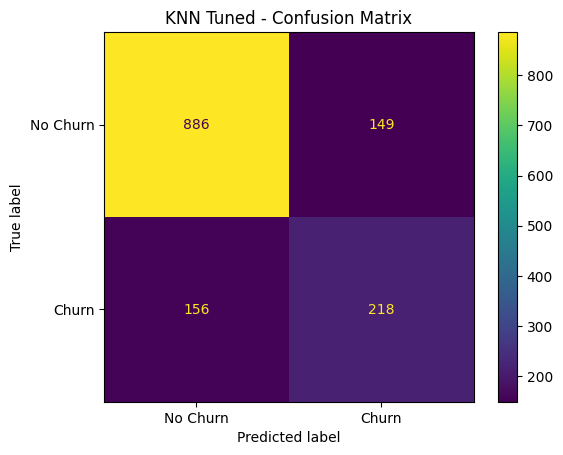

In [16]:
knn_tuned_result = evaluate_model( # danh gia mo hinh 
    y_test,
    y_predict_knn_tuned,
    y_prob_knn_tuned,
    "KNN Tuned"
)

### Nhận xét

Sau khi tối ưu siêu tham số với `n_neighbors = 21`, mô hình KNN đạt:

- **Accuracy = 78.35%**: mô hình dự đoán đúng khoảng 78% khách hàng.
- **Precision = 59.40%**: trong số khách hàng được dự đoán là Churn,
  khoảng 59% thực sự rời bỏ dịch vụ.
- **Recall = 58.29%**: mô hình phát hiện được khoảng 58% khách hàng
  thực sự Churn.
- **F1-score = 58.84%**: cho thấy sự cân bằng giữa Precision và Recall
  đã được cải thiện.
- **ROC-AUC = 82.39%**: mô hình có khả năng phân biệt tương đối tốt
  giữa khách hàng Churn và No Churn.

Từ Confusion Matrix:

- **TN = 886**: dự đoán đúng khách hàng không Churn.
- **FP = 149**: khách hàng không Churn nhưng bị dự đoán là Churn.
- **FN = 156**: khách hàng thực sự Churn nhưng mô hình không phát hiện được.
- **TP = 218**: khách hàng Churn được mô hình phát hiện chính xác.

Mặc dù vẫn còn 156 trường hợp Churn bị bỏ sót, kết quả cho thấy mô hình
KNN sau tối ưu có khả năng nhận diện khách hàng Churn tốt hơn so với
mô hình baseline.

## 5.6 Baseline vs Tuned

In [17]:
knn_metrics_comparison = compare_model_metrics(
    knn_baseline_result,
    knn_tuned_result
)

print("\nKNN Metrics Comparison:")
print(knn_metrics_comparison)


KNN Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7551  0.7835       0.0284
Precision    0.5397  0.5940       0.0543
Recall       0.5267  0.5829       0.0561
F1-score     0.5332  0.5884       0.0552
ROC-AUC      0.7821  0.8240       0.0418


In [18]:
knn_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_knn_baseline,
    y_predict_knn_tuned
)

print("\nKNN Confusion Matrix Comparison:")
print(knn_confusion_comparison)


KNN Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       867    886      19
FP       168    149     -19
FN       177    156     -21
TP       197    218      21


### Kết luận so sánh

KNN Tuned (`k = 21`) cho kết quả tốt hơn KNN Baseline (`k = 5`)
trên toàn bộ các chỉ số đánh giá.

- Accuracy tăng từ **75.51% lên 78.35%**.
- Precision tăng từ **53.97% lên 59.40%**.
- Recall tăng từ **52.67% lên 58.29%**.
- F1-score tăng từ **53.32% lên 58.84%**.
- ROC-AUC tăng từ **78.20% lên 82.39%**.

Đối với lớp Churn, số True Positive tăng từ **197 lên 218**,
trong khi False Negative giảm từ **177 xuống 156**. Như vậy,
mô hình sau tối ưu phát hiện thêm 21 khách hàng Churn và giảm
21 trường hợp Churn bị bỏ sót trên tập test.

Kết quả cho thấy việc tối ưu `n_neighbors` đã cải thiện khả năng
dự đoán của KNN. Vì vậy, KNN Tuned với `k = 21` được chọn làm
phiên bản KNN cuối cùng để so sánh với Decision Tree và Naive Bayes.

# 6. Decision Tree

## 6.1 Tổng quan

### What - DT là gì ?
DT là thuật toán học có giám sát sử dụng cấu trúc dạng cây để đưa ra quyết định dự đoán 
Mỗi nút trong cây thực hiện một điều kiện trên đặc trưng, các nhánh biểu diễn kết quả của điều kiện và các nút lá đưa ra lớp dự đoán cuối cùng

### Why - Tại sao sử dụng DT ?
- Có khả năng mô hình hóa các đặc trưng phi tuyến tính của các đặc trưng
- Ko yêu cầu giả định về phân phối dữ liệu
- Kết quả tương đối dễ giải thích thông qua cấu trúc cây
- Có thể xác định mức độ quan trọng của các đặc trưng
- Phù hợp để so sánh với knn

Tuy nhiên, cây có nguy cơ overfitting nếu cây phát triển quá sâu. Do đó cần thực hiện hyperparmeter tuning.

### When - Khi nào nên áp dụng DT ?
DT phù hợp các bài toán classification khi cần dự đoán nhãn dựa vào các đặc trưng và cần khả năng giải thích quyết định của mô hình

### Where - Được áp dụng ở đâu?
Mô hình được huấn luyện trên 'X_train' và 'y_train'
Mô hình được đánh giá trên 'X_test' và 'y_test'

### Who - Các thành phần tham gia
- `DecisionTreeClassifier`: xây dựng mô hình Decision Tree.
- Training set: dùng để huấn luyện và tối ưu mô hình.
- Test set: dùng để đánh giá mô hình cuối cùng.
- GridSearchCV: được sử dụng ở bước sau để tìm hyperparameter phù hợp.

### How – Decision Tree hoạt động như thế nào?

Decision Tree liên tục chia dữ liệu thành các nhóm dựa trên những đặc trưng
giúp phân biệt các lớp tốt nhất.

Quá trình có thể mô tả:

Data
↓
Chọn feature và điểm chia
↓
Chia dữ liệu thành các nhánh
↓
Tiếp tục chia tại các node con
↓
Leaf Node
↓
Dự đoán No Churn / Churn

Sau khi xây dựng baseline, các hyperparameter như `max_depth` sẽ được
điều chỉnh nhằm kiểm soát độ phức tạp của cây và hạn chế overfitting.

## 6.2 DT Baseline

In [19]:
dt_baseline = DecisionTreeClassifier(random_state=42)

In [20]:
dt_baseline.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

## 6.3 Đánh giá Decision Tree Baseline

Mô hình Decision Tree Baseline được đánh giá trên tập test bằng cùng
hệ thống chỉ số đã sử dụng cho KNN:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Classification Report
- Confusion Matrix

Việc sử dụng cùng phương pháp đánh giá giúp đảm bảo tính nhất quán
khi so sánh các mô hình.

In [21]:
y_predict_dt_baseline = dt_baseline.predict(X_test)
y_prob_dt_baseline =  dt_baseline.predict_proba(X_test)[:,1]

===== Desicion Tree Baseline =====
Accuracy : 0.7211
Precision: 0.4753
Recall   : 0.4893
F1-score : 0.4822
ROC-AUC  : 0.6468

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1035
           1       0.48      0.49      0.48       374

    accuracy                           0.72      1409
   macro avg       0.64      0.65      0.65      1409
weighted avg       0.72      0.72      0.72      1409

Confusion Matrix:
[[833 202]
 [191 183]]


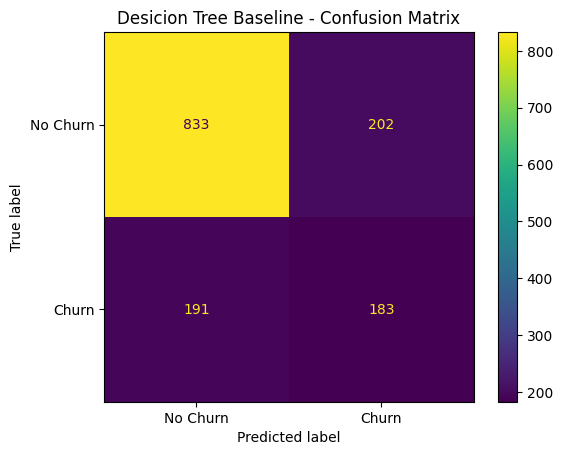

In [22]:
dt_baseline_result = evaluate_model(
  y_test,
  y_predict_dt_baseline,
  y_prob_dt_baseline,
  "Desicion Tree Baseline"
)

### Nhận xét

Decision Tree Baseline đạt:

- **Accuracy = 72.11%**
- **Precision = 47.58%**
- **Recall = 50.00%**
- **F1-score = 48.76%**
- **ROC-AUC = 65.02%**

Confusion Matrix cho thấy mô hình phát hiện đúng **187** khách hàng Churn,
nhưng đồng thời bỏ sót **187** trường hợp Churn (False Negative).

Kết quả baseline cho thấy khả năng nhận diện lớp Churn còn hạn chế.
Đặc biệt, Decision Tree với cấu hình mặc định có thể tạo cây quá phức tạp
do không giới hạn `max_depth`, làm tăng nguy cơ overfitting.

Do đó, bước tiếp theo cần kiểm soát độ phức tạp của cây và tối ưu các
hyperparameter phù hợp trước khi đưa ra kết luận về hiệu quả của
Decision Tree.

## 6.4 Tối ưu siêu tham số Decision Tree

### Decision Tree Tuning

- **What:** Tối ưu các hyperparameter kiểm soát độ phức tạp của Decision Tree.
- **Why:** Decision Tree mặc định có thể phát triển cây quá sâu và học quá sát
  training data, dẫn đến overfitting và khả năng tổng quát hóa kém.
- **When:** Thực hiện sau khi đã xây dựng và đánh giá Decision Tree Baseline.
- **Where:** Việc lựa chọn hyperparameter được thực hiện trên training set
  bằng cross-validation; test set không được sử dụng để lựa chọn tham số.
- **Who:** `GridSearchCV` kết hợp với `DecisionTreeClassifier` để tìm cấu hình
  phù hợp nhất.
- **How:** Thử nhiều tổ hợp hyperparameter bằng 5-fold cross-validation và
  sử dụng F1-score làm tiêu chí lựa chọn mô hình tốt nhất.

max_depth
    → cây được phép sâu bao nhiêu

min_samples_split
    → cần tối thiểu bao nhiêu mẫu để tiếp tục chia node

min_samples_leaf
    → mỗi leaf phải có tối thiểu bao nhiêu mẫu

### Tuning

In [23]:
param_grid_dt = {
    "criterion": ["gini", "entropy"],
    "max_depth": [3, 5, 7, 10, 15, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10]
}

grid_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid_dt,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_dt.fit(X_train, y_train);

In [24]:
print("max_depth:", grid_dt.best_estimator_.max_depth)
print("min_samples_leaf:", grid_dt.best_estimator_.min_samples_leaf)
print("min_samples_split:", grid_dt.best_estimator_.min_samples_split)
print("criterion:", grid_dt.best_estimator_.criterion)

max_depth: 5
min_samples_leaf: 10
min_samples_split: 2
criterion: entropy


In [25]:
best_dt = grid_dt.best_estimator_
print(best_dt)

DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_leaf=10,
                       random_state=42)


### Kết quả Hyperparameter Tuning

GridSearchCV lựa chọn cấu hình tốt nhất:

- `criterion = entropy`
- `max_depth = 5`
- `min_samples_leaf = 10`
- `min_samples_split = 2`

Kết quả cho thấy trong các cấu hình được thử nghiệm, tiêu chí `entropy`
kết hợp với cây có độ sâu giới hạn được lựa chọn dựa trên F1-score
qua 5-fold cross-validation.

Việc giới hạn `max_depth` và yêu cầu tối thiểu 10 mẫu tại mỗi leaf
giúp kiểm soát độ phức tạp của Decision Tree, trong khi `entropy`
được sử dụng để đánh giá chất lượng của các phép chia node.

## 6.5 DT Tuned

In [26]:
y_predict_dt_tuned = best_dt.predict(X_test)
y_prob_dt_tuned = best_dt.predict_proba(X_test)[:,1]

## 6.6 Baseline vs Tuned

===== Decision Tree Tuned =====
Accuracy : 0.7984
Precision: 0.6347
Recall   : 0.5668
F1-score : 0.5989
ROC-AUC  : 0.8321

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1035
           1       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

Confusion Matrix:
[[913 122]
 [162 212]]


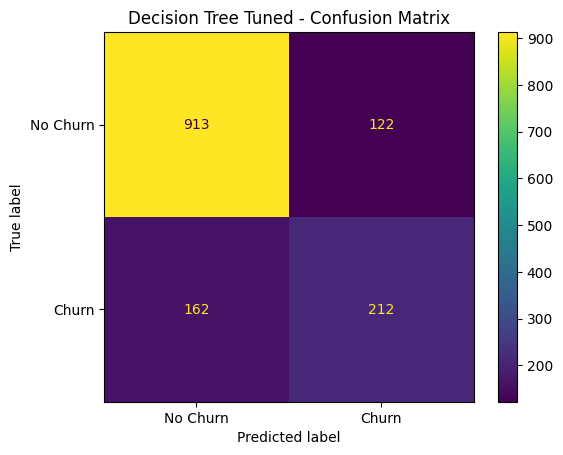

In [27]:
dt_tuned_result = evaluate_model(
  y_test,
  y_predict_dt_tuned,
  y_prob_dt_tuned,
  "Decision Tree Tuned"
)

In [28]:
dt_metrics_comparison = compare_model_metrics(
    dt_baseline_result,
    dt_tuned_result
)

print("\nDecision Tree Metrics Comparison:")
print(dt_metrics_comparison)


Decision Tree Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.7211  0.7984       0.0774
Precision    0.4753  0.6347       0.1594
Recall       0.4893  0.5668       0.0775
F1-score     0.4822  0.5989       0.1167
ROC-AUC      0.6468  0.8321       0.1853


In [29]:
dt_confusion_comparison = compare_confusion_matrix(
    y_test, 
    y_predict_dt_baseline,
    y_predict_dt_tuned
)

print("\nDecision Tree Confusion Matrix Comparison:")
print(dt_confusion_comparison)


Decision Tree Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       833    913      80
FP       202    122     -80
FN       191    162     -29
TP       183    212      29


# 7. Naive Bayes


## 7.1 Naive Bayes
1. What
- Naive Bayes (NB) là thuật toán phân loại dựa trên xác suất và định lý Bayes.
- Ví dụ đơn giản, nó xử lý bằng chứng từ Contract, tenure, MonthlyCharges, TechSupport theo giả định độc lập có điều kiện, dù trong thực tế chúng có thể liên quan nhau

2. Why
- Nhanh, đơn giản, ít computational cost và tạo được xác suất dự đoán thông qua predict_proba()
- Khác với các model trên: 
    + KNN → dựa trên khoảng cách giữa các khách hàng
    + Decision Tree → dựa trên các luật chia nhánh
    + Naive Bayes → dựa trên xác suất
- Ba cách tiếp cận classification khác nhau, phù hợp với yêu cầu rubric về so sánh nhiều thuật toán và thảo luận ưu/nhược điểm, mức phù hợp với dữ liệu.

3. When 
- NB thường hữu ích khi cần một classifier nhanh, đơn giản và làm baseline/comparison model, đặc biệt khi số feature tương đối nhiều.

---
- Naive Bayes có nhiều biến thể:
    + GaussianNB
    + MultinomialNB
    + BernoulliNB
    + CategoricalNB
- Với dữ liệu hiện tại có numerical features đã scale + categorical features đã one-hot, chúng ta có thể bắt đầu bằng **GaussianNB** như một lựa chọn thực dụng cho dữ liệu đầu vào hiện tại

## 7.2 Baseline

In [30]:
nb_baseline = GaussianNB()

In [31]:
nb_baseline.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [32]:
y_predict_nb_baseline = nb_baseline.predict(X_test)
y_prob_nb_baseline = nb_baseline.predict_proba(X_test)[:,1]

===== Naive Bayes Baseline =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


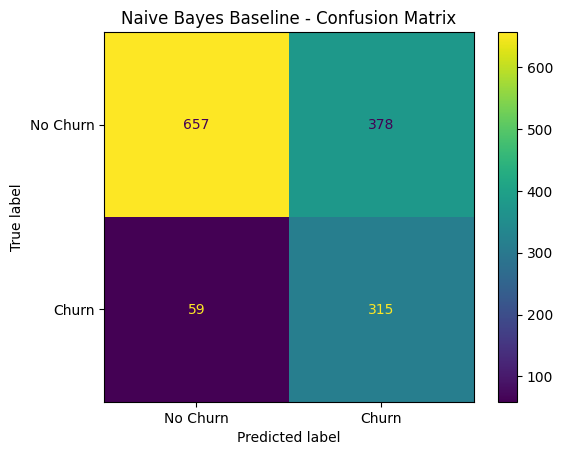

In [33]:
nb_baseline_result = evaluate_model(
    y_test,
    y_predict_nb_baseline,
    y_prob_nb_baseline,
    "Naive Bayes Baseline"
)

### Nhận xét kết quả Baseline

Mô hình Gaussian Naive Bayes Baseline đạt Accuracy = 68.99%, F1-score = 59.04% và ROC-AUC = 80.93%.

Điểm nổi bật của mô hình là Recall đạt 84.22%. Trong tổng số 374 khách hàng thực sự rời bỏ dịch vụ (Churn), mô hình dự đoán đúng 315 khách hàng và chỉ bỏ sót 59 khách hàng (False Negative). Điều này cho thấy mô hình có khả năng phát hiện khách hàng có nguy cơ rời bỏ khá tốt.

Tuy nhiên, Precision chỉ đạt 45.45%. Mô hình dự đoán nhầm 378 khách hàng không Churn thành Churn (False Positive), cho thấy số lượng cảnh báo sai còn tương đối cao.

Nhìn chung, Naive Bayes Baseline có xu hướng ưu tiên phát hiện nhiều khách hàng Churn, giúp giảm số trường hợp bỏ sót khách hàng có nguy cơ rời bỏ, nhưng phải đánh đổi bằng việc gia tăng số lượng False Positive. Trong bối cảnh kinh doanh, điều này có thể giúp doanh nghiệp hạn chế bỏ sót khách hàng cần giữ chân, nhưng đồng thời có thể làm tăng chi phí nếu triển khai chương trình giữ chân cho những khách hàng thực tế không có ý định rời bỏ.

## 7.3 Hyperparameter Tuning

`var_smoothing ?`

GaussianNB giả định giá trị của mỗi feature trong từng class tuân theo phân phối Gaussian. Khi tính xác suất, model sử dụng mean và variance của feature.
Vấn đề là nếu variance của một feature quá nhỏ, việc tính xác suất có thể trở nên không ổn định. var_smoothing thêm một lượng nhỏ vào variance để làm phép tính ổn định hơn.

default của GaussinNB là var_smoothing=1e-9

Sau khi xây dựng mô hình Baseline, `GridSearchCV` được sử dụng để tìm giá trị `var_smoothing` phù hợp cho Gaussian Naive Bayes.

`var_smoothing` giúp ổn định việc ước lượng phương sai trong Gaussian Naive Bayes bằng cách bổ sung một lượng nhỏ vào variance của các đặc trưng.

Quá trình tuning sử dụng 5-fold Cross-Validation (`cv=5`) trên tập training. F1-score được chọn làm tiêu chí đánh giá do dữ liệu Customer Churn bị mất cân bằng và cần cân bằng giữa Precision và Recall.

Tập test không được sử dụng trong quá trình lựa chọn hyperparameter nhằm đảm bảo đánh giá cuối cùng được thực hiện trên dữ liệu chưa được sử dụng để tối ưu mô hình.


In [34]:
param_grid_nb = {
    "var_smoothing": np.logspace(-12, -6, 13)
}

grid_nb = GridSearchCV(
    estimator=GaussianNB(),
    param_grid=param_grid_nb,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_nb.fit(X_train, y_train);

In [35]:
print("Best Parameters:", grid_nb.best_params_)
print("Best CV F1-score:", round(grid_nb.best_score_, 4))

Best Parameters: {'var_smoothing': np.float64(1e-12)}
Best CV F1-score: 0.5953


## 7.4 Naive Bayes Tuned

In [36]:
best_nb = grid_nb.best_estimator_
print(best_nb)

GaussianNB(var_smoothing=np.float64(1e-12))


In [37]:
y_predict_nb_tuned = best_nb.predict(X_test)
y_prob_nb_tuned = best_nb.predict_proba(X_test)[:,1]

===== Naive Bayes Tuned =====
Accuracy : 0.6899
Precision: 0.4545
Recall   : 0.8422
F1-score : 0.5904
ROC-AUC  : 0.8093

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.63      0.75      1035
           1       0.45      0.84      0.59       374

    accuracy                           0.69      1409
   macro avg       0.69      0.74      0.67      1409
weighted avg       0.79      0.69      0.71      1409

Confusion Matrix:
[[657 378]
 [ 59 315]]


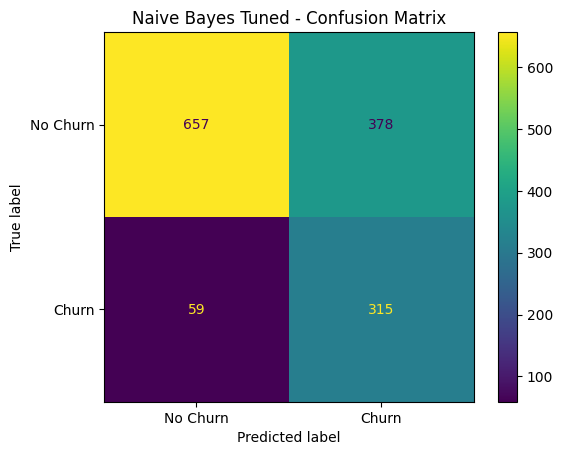

In [38]:
nb_tuned_result = evaluate_model(
    y_test, 
    y_predict_nb_tuned,
    y_prob_nb_tuned,
    "Naive Bayes Tuned"
)

### Nhận xét sau Hyperparameter Tuning

Sau quá trình Hyperparameter Tuning bằng GridSearchCV, giá trị `var_smoothing = 1e-12` được lựa chọn với F1-score trung bình qua 5-fold Cross-Validation đạt 0.5953.

Tuy nhiên, khi đánh giá mô hình đã tuning trên tập test, các chỉ số Accuracy, Precision, Recall, F1-score và ROC-AUC không thay đổi so với mô hình Baseline. Confusion Matrix cũng giữ nguyên với 657 TN, 378 FP, 59 FN và 315 TP.

Kết quả cho thấy việc điều chỉnh `var_smoothing` trong phạm vi khảo sát chưa tạo ra sự cải thiện đáng kể đối với khả năng phân loại của Gaussian Naive Bayes trên tập dữ liệu hiện tại.

Mặc dù vậy, mô hình vẫn duy trì Recall cao ở mức 84.22%, cho thấy khả năng phát hiện phần lớn khách hàng thực sự Churn. Đổi lại, Precision chỉ đạt 45.45% và số lượng False Positive còn cao, thể hiện sự đánh đổi giữa khả năng phát hiện khách hàng Churn và số lượng cảnh báo sai.

In [39]:
nb_metrics_comparison = compare_model_metrics(
    nb_baseline_result,
    nb_tuned_result
)

print("\nNaive Bayes Metrics Comparison:")
print(nb_metrics_comparison)


Naive Bayes Metrics Comparison:
           Baseline   Tuned  Improvement
Accuracy     0.6899  0.6899          0.0
Precision    0.4545  0.4545          0.0
Recall       0.8422  0.8422          0.0
F1-score     0.5904  0.5904          0.0
ROC-AUC      0.8093  0.8093          0.0


In [40]:
nb_confusion_comparison = compare_confusion_matrix(
    y_test,
    y_predict_nb_baseline,
    y_predict_nb_tuned
)

print("\nNaive Bayes Confusion Matrix Comparison:")
print(nb_confusion_comparison)


Naive Bayes Confusion Matrix Comparison:
    Baseline  Tuned  Change
TN       657    657       0
FP       378    378       0
FN        59     59       0
TP       315    315       0


# 8. Model Evaluation & Compariso

## 8.1 Cross-validation
Sau khi hoàn thành quá trình xây dựng và tuning ba mô hình KNN, Decision Tree và Naive Bayes, Cross-validation được sử dụng để đánh giá hiệu suất và độ ổn định của các mô hình.

Trong phần này, Stratified 5-Fold Cross-Validation được sử dụng trên tập training nhằm duy trì tỷ lệ giữa hai lớp Churn và No Churn trong mỗi fold.

Các mô hình sẽ được đánh giá bằng Precision, Recall, F1-score và ROC-AUC. Kết quả được báo cáo dưới dạng giá trị trung bình (Mean) và độ lệch chuẩn (Standard Deviation - Std) qua 5 folds.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("StratifiedKFold CV setup complete.")
print(cv)


StratifiedKFold CV setup complete.
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


n_splits=5 nghĩa là chia training data thành 5 phần

Lần 1: [**TEST**] [TRAIN] [TRAIN] [TRAIN] [TRAIN]

Lần 2: [TRAIN] [**TEST**] [TRAIN] [TRAIN] [TRAIN]

Lần 3: [TRAIN] [TRAIN] [**TEST**] [TRAIN] [TRAIN]

Lần 4: [TRAIN] [TRAIN] [TRAIN] [**TEST**] [TRAIN]

Lần 5: [TRAIN] [TRAIN] [TRAIN] [TRAIN] [**TEST**]

In [42]:
print(f'knn {best_knn}')
print(f'dt {best_dt}')
print(f'nb {best_nb}')

knn KNeighborsClassifier(n_neighbors=21)
dt DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_leaf=10,
                       random_state=42)
nb GaussianNB(var_smoothing=np.float64(1e-12))


In [43]:
models = {
    "knn": best_knn,
    "dt": best_dt,
    "nb": best_nb
}

In [44]:
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [45]:
cv_results = {}

for name, model in models.items():
    score = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=True
    )
    cv_results[name] = score
        

In [46]:
print("\nCross-validation results:")
for name, score in cv_results.items():
    print(f"\n{name.upper()} Model:")
    for metric in scoring.keys():
        train_score = np.mean(score[f'train_{metric}'])
        test_score = np.mean(score[f'test_{metric}'])
        print(f"{metric.capitalize()} - Train: {train_score:.4f}, Test: {test_score:.4f}")


Cross-validation results:

KNN Model:
Precision - Train: 0.6514, Test: 0.6131
Recall - Train: 0.6142, Test: 0.5819
F1 - Train: 0.6322, Test: 0.5967
Roc_auc - Train: 0.8609, Test: 0.8291

DT Model:
Precision - Train: 0.6518, Test: 0.6383
Recall - Train: 0.5463, Test: 0.5211
F1 - Train: 0.5918, Test: 0.5713
Roc_auc - Train: 0.8537, Test: 0.8314

NB Model:
Precision - Train: 0.4580, Test: 0.4591
Recall - Train: 0.8488, Test: 0.8475
F1 - Train: 0.5950, Test: 0.5955
Roc_auc - Train: 0.8226, Test: 0.8221


In [47]:
for name, scores in cv_results.items():

    print(f"\n{name} Model:")

    for metric in ["precision", "recall", "f1", "roc_auc"]:

        test_scores = scores[f"test_{metric}"]

        print(
            f"{metric.capitalize():9s}: "
            f"{test_scores.mean():.4f} ± {test_scores.std():.4f}"
        )


knn Model:
Precision: 0.6131 ± 0.0204
Recall   : 0.5819 ± 0.0286
F1       : 0.5967 ± 0.0199
Roc_auc  : 0.8291 ± 0.0102

dt Model:
Precision: 0.6383 ± 0.0241
Recall   : 0.5211 ± 0.0552
F1       : 0.5713 ± 0.0300
Roc_auc  : 0.8314 ± 0.0092

nb Model:
Precision: 0.4591 ± 0.0066
Recall   : 0.8475 ± 0.0208
F1       : 0.5955 ± 0.0081
Roc_auc  : 0.8221 ± 0.0125


### Nhận xét kết quả Cross-validation

Kết quả Stratified 5-Fold Cross-Validation cho thấy ba mô hình có những ưu điểm và hạn chế khác nhau.

**KNN** đạt F1-score trung bình cao nhất với 0.5967 ± 0.0199. Precision đạt 0.6131 và Recall đạt 0.5819, cho thấy mô hình duy trì sự cân bằng tương đối tốt giữa khả năng phát hiện khách hàng Churn và độ chính xác của các dự đoán Churn.

**Decision Tree** đạt Precision cao nhất (0.6383 ± 0.0241) và ROC-AUC cao nhất (0.8314 ± 0.0092). Tuy nhiên, Recall chỉ đạt 0.5211 ± 0.0552 và có độ lệch chuẩn lớn nhất trong ba mô hình ở chỉ số này, cho thấy khả năng phát hiện khách hàng Churn của Decision Tree có sự dao động đáng kể hơn giữa các folds.

**Naive Bayes** đạt Recall cao nhất với 0.8475 ± 0.0208, cho thấy khả năng phát hiện phần lớn khách hàng thực sự Churn. Mô hình cũng có F1-score khá ổn định với 0.5955 ± 0.0081, đây là độ lệch chuẩn F1 thấp nhất trong ba mô hình. Tuy nhiên, Precision chỉ đạt 0.4591, cho thấy mô hình tạo ra tương đối nhiều dự đoán False Positive.

Nhìn chung, chưa có mô hình nào vượt trội hoàn toàn trên tất cả các tiêu chí. KNN đạt F1-score trung bình cao nhất, Decision Tree nổi bật về Precision và ROC-AUC, trong khi Naive Bayes nổi bật về Recall và độ ổn định của F1-score. Vì vậy, việc lựa chọn mô hình cuối cùng chưa được thực hiện tại bước này và cần kết hợp thêm kết quả trên tập test, phân tích lỗi False Positive/False Negative và ý nghĩa kinh doanh.

## 8.2 Model Performance Comparison

Sau khi thực hiện Stratified 5-Fold Cross-Validation, kết quả Cross-validation được kết hợp với kết quả đánh giá trên tập test để so sánh hiệu suất của ba mô hình KNN, Decision Tree và Naive Bayes.

Việc so sánh không chỉ dựa trên một chỉ số duy nhất mà xem xét đồng thời Precision, Recall, F1-score, ROC-AUC và độ ổn định của mô hình qua các folds.

Ở giai đoạn này, mục tiêu là phân tích ưu và nhược điểm của từng mô hình. Mô hình cuối cùng chưa được lựa chọn cho đến khi hoàn thành Error Analysis và phân tích ý nghĩa kinh doanh.

In [48]:
test_comparison = pd.DataFrame({
    "Model": [
        "KNN",
        "Decision Tree",
        "Naive Bayes"
    ],

    "Precision": [
        knn_tuned_result["Precision"],
        dt_tuned_result["Precision"],
        nb_tuned_result["Precision"]
    ],

    "Recall": [
        knn_tuned_result["Recall"],
        dt_tuned_result["Recall"],
        nb_tuned_result["Recall"]
    ],

    "F1-score": [
        knn_tuned_result["F1-score"],
        dt_tuned_result["F1-score"],
        nb_tuned_result["F1-score"]
    ],

    "ROC-AUC": [
        knn_tuned_result["ROC-AUC"],
        dt_tuned_result["ROC-AUC"],
        nb_tuned_result["ROC-AUC"]
    ]
})

test_comparison.round(4)

,Model,Precision,Recall,F1-score,ROC-AUC
0,KNN,0.5940,0.5829,0.5884,0.8240
1,Decision Tree,0.6347,0.5668,0.5989,0.8321
2,Naive Bayes,0.4545,0.8422,0.5904,0.8093


### Nhận xét Model Performance Comparison

Kết quả đánh giá cho thấy không có mô hình nào vượt trội hoàn toàn trên tất cả các tiêu chí.

**Decision Tree** đạt kết quả tốt nhất trên tập test về Precision (0.6347), F1-score (0.5989) và ROC-AUC (0.8321). Đặc biệt, ROC-AUC trên tập test (0.8321) gần với ROC-AUC trung bình qua Cross-validation (0.8314 ± 0.0092), cho thấy khả năng phân biệt hai lớp của mô hình tương đối ổn định. Tuy nhiên, CV F1-score chỉ đạt 0.5713 ± 0.0300 và thấp hơn kết quả trên tập test.

**KNN** đạt F1-score trung bình qua Cross-validation cao nhất (0.5967 ± 0.0199). Kết quả F1-score trên tập test (0.5884) cũng tương đối gần với kết quả Cross-validation, cho thấy hiệu suất khá nhất quán. Tuy nhiên, Precision và ROC-AUC trên tập test vẫn thấp hơn Decision Tree.

**Naive Bayes** nổi bật với Recall trên tập test đạt 0.8422 và F1-score qua Cross-validation đạt 0.5955 ± 0.0081. Độ lệch chuẩn F1-score thấp nhất trong ba mô hình cho thấy hiệu suất F1 khá ổn định giữa các folds. Tuy nhiên, Precision chỉ đạt 0.4545 và ROC-AUC trên tập test đạt 0.8093, thấp nhất trong ba mô hình.

Nhìn chung, Decision Tree hiện có hiệu suất tổng thể tốt trên tập test và khả năng phân biệt hai lớp tốt, KNN thể hiện sự cân bằng tương đối tốt giữa Precision và Recall, trong khi Naive Bayes có ưu thế rõ rệt về khả năng phát hiện khách hàng Churn. Do đó, chưa lựa chọn mô hình cuối cùng tại bước này. Cần tiếp tục phân tích False Positive và False Negative để đánh giá tác động của từng loại sai số trong bối cảnh kinh doanh.

## 8.3 Error Analysis

Bên cạnh các chỉ số Precision, Recall, F1-score và ROC-AUC, việc phân tích các trường hợp dự đoán sai giúp hiểu rõ hơn hành vi của từng mô hình.

Trong bài toán Customer Churn, hai loại lỗi quan trọng là:

- **False Positive (FP):** Khách hàng thực tế không Churn nhưng mô hình dự đoán Churn. Điều này có thể dẫn đến việc doanh nghiệp triển khai các chương trình giữ chân không cần thiết.
- **False Negative (FN):** Khách hàng thực tế Churn nhưng mô hình dự đoán No Churn. Điều này khiến doanh nghiệp có nguy cơ bỏ sót khách hàng cần được giữ chân.

Do đó, Confusion Matrix của ba mô hình tuned được so sánh để đánh giá sự đánh đổi giữa False Positive và False Negative.

In [50]:
cm_knn = confusion_matrix(y_test, y_predict_knn_tuned)
cm_dt = confusion_matrix(y_test, y_predict_dt_tuned)
cm_nb = confusion_matrix(y_test, y_predict_nb_tuned)

tn_knn, fp_knn, fn_knn, tp_knn = cm_knn.ravel()
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
tn_nb, fp_nb, fn_nb, tp_nb = cm_nb.ravel()

print("KNN:", tn_knn, fp_knn, fn_knn, tp_knn)
print("DT :", tn_dt, fp_dt, fn_dt, tp_dt)
print("NB :", tn_nb, fp_nb, fn_nb, tp_nb)

KNN: 886 149 156 218
DT : 913 122 162 212
NB : 657 378 59 315


In [51]:
error_comparison = pd.DataFrame({
    "Model": [
        "KNN",
        "Decision Tree",
        "Naive Bayes"
    ],

    "TN": [
        tn_knn,
        tn_dt,
        tn_nb
    ],

    "FP": [
        fp_knn,
        fp_dt,
        fp_nb
    ],

    "FN": [
        fn_knn,
        fn_dt,
        fn_nb
    ],

    "TP": [
        tp_knn,
        tp_dt,
        tp_nb
    ]
})

error_comparison

,Model,TN,FP,FN,TP
0,KNN,886,149,156,218
1,Decision Tree,913,122,162,212
2,Naive Bayes,657,378,59,315


### Nhận xét Error Analysis

Kết quả Error Analysis cho thấy ba mô hình có sự đánh đổi rõ rệt giữa False Positive (FP) và False Negative (FN).

**Decision Tree** có số False Positive thấp nhất với 122 trường hợp, cho thấy mô hình ít dự đoán nhầm khách hàng không Churn thành Churn. Tuy nhiên, mô hình có 162 False Negative, cao nhất trong ba mô hình, nghĩa là bỏ sót tương đối nhiều khách hàng thực sự Churn.

**Naive Bayes** thể hiện xu hướng ngược lại. Mô hình chỉ có 59 False Negative và phát hiện đúng 315 khách hàng Churn, cho thấy khả năng hạn chế bỏ sót khách hàng có nguy cơ rời bỏ tốt nhất. Tuy nhiên, số False Positive lên tới 378, cao hơn đáng kể so với hai mô hình còn lại. Điều này có thể dẫn đến nhiều cảnh báo Churn không chính xác.

**KNN** nằm tương đối giữa hai mô hình với 149 False Positive và 156 False Negative. Mô hình không giảm False Negative mạnh như Naive Bayes nhưng tạo ra ít False Positive hơn đáng kể.

Nhìn chung, kết quả cho thấy tồn tại sự đánh đổi giữa việc phát hiện nhiều khách hàng Churn và việc hạn chế cảnh báo sai. Nếu ưu tiên giảm số khách hàng Churn bị bỏ sót, Naive Bayes có lợi thế về False Negative. Ngược lại, Decision Tree có lợi thế khi cần hạn chế False Positive. Vì vậy, cần xem xét chi phí và tác động kinh doanh của hai loại lỗi trước khi lựa chọn mô hình cuối cùng.

## 8.4

In [56]:
# Đọc lại dữ liệu gốc
df_raw = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Xử lý TotalCharges giống bước preprocessing ban đầu
df_raw["TotalCharges"] = pd.to_numeric(
    df_raw["TotalCharges"],
    errors="coerce"
)

df_raw["TotalCharges"] = df_raw["TotalCharges"].fillna(0)

# Target
df_raw["Churn"] = df_raw["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Features và target giống notebook preprocessing
X_raw = df_raw.drop(columns=["customerID", "Churn"])
y_raw = df_raw["Churn"]

# Tái tạo chính xác train/test split
_, X_test_raw, _, y_test_raw = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    stratify=y_raw,
    random_state=42
)

print("X_test_raw shape :", X_test_raw.shape)
print("X_test shape     :", X_test.shape)
print("y_test_raw shape :", y_test_raw.shape)
print("y_test shape     :", y_test.shape)

X_test_raw shape : (1409, 19)
X_test shape     : (1409, 40)
y_test_raw shape : (1409,)
y_test shape     : (1409,)


In [57]:
import numpy as np

same_target = np.array_equal(
    y_test_raw.to_numpy(),
    np.asarray(y_test).ravel()
)

print("Target order identical:", same_target)

Target order identical: True


In [58]:
X_test_raw.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35


In [60]:
error_analysis = X_test_raw.reset_index(drop=True).copy()

# Thêm nhãn thực tế
error_analysis["Actual_Churn"] = np.asarray(y_test).ravel()

# Thêm prediction của từng model
error_analysis["KNN_Prediction"] = y_predict_knn_tuned
error_analysis["DT_Prediction"] = y_predict_dt_tuned
error_analysis["NB_Prediction"] = y_predict_nb_tuned

# Xác định TP / TN / FP / FN
error_analysis["KNN_Result"] = [
    classify_prediction(y, pred)
    for y, pred in zip(
        error_analysis["Actual_Churn"],
        error_analysis["KNN_Prediction"]
    )
]

error_analysis["DT_Result"] = [
    classify_prediction(y, pred)
    for y, pred in zip(
        error_analysis["Actual_Churn"],
        error_analysis["DT_Prediction"]
    )
]

error_analysis["NB_Result"] = [
    classify_prediction(y, pred)
    for y, pred in zip(
        error_analysis["Actual_Churn"],
        error_analysis["NB_Prediction"]
    )
]

error_analysis.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,KNN_Prediction,DT_Prediction,NB_Prediction,KNN_Result,DT_Result,NB_Result
0,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Credit card (automatic),114.05,8468.20,0,0,0,0,TN,TN,TN
1,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Credit card (automatic),100.15,908.55,0,1,1,1,FP,FP,FP
2,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),78.35,3211.20,0,0,0,0,TN,TN,TN
3,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,Electronic check,78.20,1468.75,0,0,1,1,TN,FP,FP
4,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Credit card (automatic),82.65,5919.35,0,0,0,0,TN,TN,TN


In [61]:
for model in ["KNN", "DT", "NB"]:
    print(f"\n{model}")
    print(
        error_analysis[f"{model}_Result"]
        .value_counts()
    )


KNN
KNN_Result
TN    886
TP    218
FN    156
FP    149
Name: count, dtype: int64

DT
DT_Result
TN    913
TP    212
FN    162
FP    122
Name: count, dtype: int64

NB
NB_Result
TN    657
FP    378
TP    315
FN     59
Name: count, dtype: int64


In [62]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for model in ["KNN", "DT", "NB"]:

    print(f"\n===== {model} =====")

    error_numeric = (
        error_analysis
        .groupby(f"{model}_Result")[numeric_features]
        .mean()
        .round(2)
    )

    print(error_numeric.loc[["FP", "FN"]])


===== KNN =====
            tenure  MonthlyCharges  TotalCharges
KNN_Result                                      
FP           17.10           80.67       1497.44
FN           24.55           64.11       2071.62

===== DT =====
           tenure  MonthlyCharges  TotalCharges
DT_Result                                      
FP          10.14           75.55        846.28
FN          27.77           68.46       2371.13

===== NB =====
           tenure  MonthlyCharges  TotalCharges
NB_Result                                      
FP          23.88           72.81       1880.13
FN          30.36           60.34       2670.53


In [63]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

for model in ["KNN", "DT", "NB"]:

    print(f"\n===== {model} =====")

    for feature in categorical_features:

        print(f"\n{feature}")

        table = pd.crosstab(
            error_analysis.loc[
                error_analysis[f"{model}_Result"].isin(["FP", "FN"]),
                f"{model}_Result"
            ],
            error_analysis.loc[
                error_analysis[f"{model}_Result"].isin(["FP", "FN"]),
                feature
            ],
            normalize="index"
        ) * 100

        print(table.round(1))


===== KNN =====

Contract
Contract    Month-to-month  One year  Two year
KNN_Result                                    
FN                    72.4      21.8       5.8
FP                    96.6       2.7       0.7

InternetService
InternetService   DSL  Fiber optic    No
KNN_Result                              
FN               44.9         39.1  16.0
FP               14.8         85.2   0.0

PaymentMethod
PaymentMethod  Bank transfer (automatic)  Credit card (automatic)  \
KNN_Result                                                          
FN                                  23.7                     17.9   
FP                                  11.4                     10.7   

PaymentMethod  Electronic check  Mailed check  
KNN_Result                                     
FN                         33.3          25.0  
FP                         62.4          15.4  

TechSupport
TechSupport    No  No internet service   Yes
KNN_Result                                  
FN           53.2

In [65]:
def segment_error_rate(data, model, feature):

    rows = []

    for category in data[feature].unique():

        segment = data[data[feature] == category]

        actual_negative = segment[
            segment["Actual_Churn"] == 0
        ]

        actual_positive = segment[
            segment["Actual_Churn"] == 1
        ]

        fp_count = (
            actual_negative[f"{model}_Result"] == "FP"
        ).sum()

        fn_count = (
            actual_positive[f"{model}_Result"] == "FN"
        ).sum()

        fp_rate = (
            fp_count / len(actual_negative)
            if len(actual_negative) > 0 else 0
        )

        fn_rate = (
            fn_count / len(actual_positive)
            if len(actual_positive) > 0 else 0
        )

        rows.append({
            feature: category,

            "Actual No Churn": len(actual_negative),
            "FP": fp_count,
            "FP Rate": fp_rate,

            "Actual Churn": len(actual_positive),
            "FN": fn_count,
            "FN Rate": fn_rate
        })

    return pd.DataFrame(rows)

In [66]:
for model in ["KNN", "DT", "NB"]:

    print(f"\n===== {model} - Contract =====")

    display(
        segment_error_rate(
            error_analysis,
            model,
            "Contract"
        ).round(4)
    )


===== KNN - Contract =====


,Contract,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,Two year,327,1,0.0031,9,9,1.0000
1,Month-to-month,444,144,0.3243,329,113,0.3435
2,One year,264,4,0.0152,36,34,0.9444



===== DT - Contract =====


,Contract,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,Two year,327,0,0.0000,9,9,1.0000
1,Month-to-month,444,122,0.2748,329,117,0.3556
2,One year,264,0,0.0000,36,36,1.0000



===== NB - Contract =====


,Contract,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,Two year,327,0,0.0000,9,9,1.0000
1,Month-to-month,444,344,0.7748,329,24,0.0729
2,One year,264,34,0.1288,36,26,0.7222


### Phân tích lỗi theo loại hợp đồng (Contract)

Kết quả phân tích theo loại hợp đồng cho thấy sự khác biệt rõ rệt trong hành vi dự đoán của ba mô hình.

Nhóm **Month-to-month** là nhóm đáng chú ý nhất do chiếm phần lớn khách hàng Churn trong tập test (329 trên tổng số 374 khách hàng Churn).

Đối với nhóm này, KNN có False Negative Rate là 34.35% và False Positive Rate là 32.43%. Decision Tree có False Negative Rate tương tự ở mức 35.56%, nhưng False Positive Rate thấp hơn, đạt 27.48%.

Naive Bayes có hành vi khác biệt rõ rệt. Mô hình chỉ bỏ sót 24 trong tổng số 329 khách hàng Month-to-month thực sự Churn, tương ứng False Negative Rate 7.29%. Tuy nhiên, mô hình dự đoán nhầm 344 trong tổng số 444 khách hàng Month-to-month không Churn, tương ứng False Positive Rate 77.48%.

Đối với nhóm One-year và Two-year, cả ba mô hình có False Negative Rate cao. Tuy nhiên, số lượng khách hàng Churn thuộc các nhóm này trong tập test tương đối nhỏ (36 khách One-year và 9 khách Two-year), do đó các tỷ lệ này cần được diễn giải cùng với kích thước mẫu.

Nhìn chung, kết quả cho thấy Naive Bayes có xu hướng dự đoán Churn mạnh đối với nhóm Month-to-month, giúp giảm đáng kể số khách hàng Churn bị bỏ sót nhưng đồng thời tạo ra nhiều False Positive. Decision Tree có xu hướng thận trọng hơn khi dự đoán Churn, giúp hạn chế False Positive nhưng bỏ sót nhiều khách hàng Churn hơn.

In [67]:
business_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

segment_results = []

for model in ["KNN", "DT", "NB"]:

    for feature in business_features:

        result = segment_error_rate(
            error_analysis,
            model,
            feature
        )

        result.insert(0, "Feature", feature)
        result.insert(0, "Model", model)

        # Đổi tên category thành một cột chung
        result = result.rename(
            columns={feature: "Category"}
        )

        segment_results.append(result)

business_error_summary = pd.concat(
    segment_results,
    ignore_index=True
)

business_error_summary.round(4)

,Model,Feature,Category,Actual No Churn,FP,FP Rate,Actual Churn,FN,FN Rate
0,KNN,Contract,Two year,327,1,0.0031,9,9,1.0000
1,KNN,Contract,Month-to-month,444,144,0.3243,329,113,0.3435
2,KNN,Contract,One year,264,4,0.0152,36,34,0.9444
3,KNN,InternetService,Fiber optic,361,127,0.3518,252,61,0.2421
4,KNN,InternetService,DSL,387,22,0.0568,97,70,0.7216
5,KNN,InternetService,No,287,0,0.0000,25,25,1.0000
6,KNN,PaymentMethod,Credit card (automatic),258,16,0.0620,51,28,0.5490
7,KNN,PaymentMethod,Electronic check,268,93,0.3470,206,52,0.2524
8,KNN,PaymentMethod,Bank transfer (automatic),243,17,0.0700,57,37,0.6491
9,KNN,PaymentMethod,Mailed check,266,23,0.0865,60,39,0.6500


### Business Interpretation of Model Errors

Phân tích lỗi theo đặc điểm khách hàng cho thấy sự khác biệt rõ rệt trong hành vi của ba mô hình.

KNN và Decision Tree có xu hướng nhận diện Churn tốt hơn ở các nhóm khách hàng có các đặc điểm thường gắn với rủi ro Churn cao trong dữ liệu, chẳng hạn như hợp đồng Month-to-month, sử dụng Fiber optic, thanh toán bằng Electronic check, không sử dụng TechSupport hoặc OnlineSecurity. Tuy nhiên, hai mô hình có False Negative Rate cao hơn ở một số nhóm khác, cho thấy chúng có thể bỏ sót những khách hàng Churn có profile ít điển hình hơn.

Decision Tree đặc biệt có xu hướng dự đoán Churn thận trọng. Điều này giúp mô hình hạn chế False Positive nhưng đồng thời làm tăng nguy cơ bỏ sót khách hàng thực sự Churn.

Naive Bayes thể hiện hành vi ngược lại. Trong các segment có nhiều khách hàng Churn, mô hình đạt False Negative Rate rất thấp. Ví dụ, FN Rate chỉ là 7.29% đối với Month-to-month, 8.33% đối với Fiber optic và 6.80% đối với Electronic check. Tuy nhiên, False Positive Rate tương ứng lại rất cao, lần lượt là 77.48%, 60.39% và 68.28%.

Kết quả cho thấy tồn tại sự đánh đổi rõ ràng giữa việc phát hiện nhiều khách hàng có nguy cơ Churn và việc hạn chế các cảnh báo sai. Vì False Negative có thể dẫn đến bỏ lỡ cơ hội giữ chân một khách hàng thực sự rời dịch vụ, trong khi False Positive có thể dẫn đến chi phí giữ chân không cần thiết, việc lựa chọn mô hình không nên chỉ dựa trên Accuracy hoặc F1-score mà cần xem xét chi phí kinh doanh của hai loại lỗi.

Ngoài ra, các tỷ lệ lỗi cần được diễn giải cùng với kích thước của từng segment. Một số nhóm như Two-year có số lượng khách hàng Churn tương đối nhỏ trong tập test, do đó tỷ lệ FN cao không nhất thiết phản ánh hiệu suất tổng thể của mô hình trên toàn bộ khách hàng.

## 8.5

In [68]:
print("KNN :", best_knn.predict_proba(X_train)[:5, 1])
print("DT  :", best_dt.predict_proba(X_train)[:5, 1])
print("NB  :", best_nb.predict_proba(X_train)[:5, 1])   

KNN : [0.38095238 0.38095238 0.         0.0952381  0.42857143]
DT  : [0.38461538 0.37134503 0.01267427 0.01267427 0.52112676]
NB  : [9.99766983e-01 9.98519755e-01 9.19164198e-12 5.35454713e-08
 9.99972172e-01]


### 8.5.1

In [69]:
from sklearn.model_selection import cross_val_predict

oof_prob_knn = cross_val_predict(
    best_knn,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_prob_dt = cross_val_predict(
    best_dt,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_prob_nb = cross_val_predict(
    best_nb,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("KNN:", oof_prob_knn[:5])
print("DT :", oof_prob_dt[:5])
print("NB :", oof_prob_nb[:5])

print("\nShapes:")
print(oof_prob_knn.shape)
print(oof_prob_dt.shape)
print(oof_prob_nb.shape)

KNN: [0.57142857 0.42857143 0.04761905 0.0952381  0.57142857]
DT : [0.13812155 0.55925926 0.         0.         0.49344978]
NB : [9.99755294e-01 9.98517964e-01 5.95767764e-12 3.12010079e-08
 9.99971721e-01]

Shapes:
(5634,)
(5634,)
(5634,)


In [75]:
oof_models = {
    "KNN": oof_prob_knn,
    "DT": oof_prob_dt,
    "NB": oof_prob_nb
}

cost_scenarios = [1, 2, 5, 10]

all_cost_sensitivity = []

for model_name, probabilities in oof_models.items():

    for cost_fn in cost_scenarios:

        results = threshold_analysis(
            y_train,
            probabilities,
            cost_fn=cost_fn,
            cost_fp=1
        )

        best_row = results.loc[
            results["Total Cost"].idxmin()
        ]

        all_cost_sensitivity.append({
            "Model": model_name,
            "FN:FP Cost Ratio": f"{cost_fn}:1",
            "Best Threshold": best_row["Threshold"],
            "FP": int(best_row["FP"]),
            "FN": int(best_row["FN"]),
            "Precision": best_row["Precision"],
            "Recall": best_row["Recall"],
            "F1": best_row["F1"],
            "Minimum Cost": best_row["Total Cost"]
        })

cost_sensitivity_table = pd.DataFrame(
    all_cost_sensitivity
)

display(
    cost_sensitivity_table.round(4)
)

,Model,FN:FP Cost Ratio,Best Threshold,FP,FN,Precision,Recall,F1,Minimum Cost
0,KNN,1:1,0.53,441,725,0.6358,0.5151,0.5691,1166.0
1,KNN,2:1,0.39,829,456,0.5562,0.6950,0.6179,1741.0
2,KNN,5:1,0.20,1654,191,0.4408,0.8722,0.5857,2609.0
3,KNN,10:1,0.05,2576,46,0.3600,0.9692,0.5250,3036.0
4,DT,1:1,0.50,446,716,0.6359,0.5211,0.5728,1162.0
5,DT,2:1,0.34,940,390,0.5403,0.7391,0.6243,1720.0
6,DT,5:1,0.14,1834,134,0.4260,0.9104,0.5804,2504.0
7,DT,10:1,0.07,2405,60,0.3737,0.9599,0.5380,3005.0
8,NB,1:1,0.99,1166,310,0.5040,0.7926,0.6162,1476.0
9,NB,2:1,0.99,1166,310,0.5040,0.7926,0.6162,1786.0


In [74]:
def threshold_analysis(
    y_true,
    probabilities,
    cost_fn=5,
    cost_fp=1
):
    results = []

    thresholds = np.arange(0.01, 1.00, 0.01)

    for threshold in thresholds:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            y_pred
        ).ravel()

        total_cost = (
            fn * cost_fn +
            fp * cost_fp
        )

        results.append({
            "Threshold": threshold,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "Total Cost": total_cost
        })

    return pd.DataFrame(results)

In [ ]:
# Probability trên TEST SET
test_prob_knn = best_knn.predict_proba(X_test)[:, 1]
test_prob_dt  = best_dt.predict_proba(X_test)[:, 1]
test_prob_nb  = best_nb.predict_proba(X_test)[:, 1]

# Threshold đã được chọn từ OOF TRAIN
locked_thresholds = {
    "KNN": 0.20,
    "DT": 0.14,
    "NB": 0.89
}

test_probabilities = {
    "KNN": test_prob_knn,
    "DT": test_prob_dt,
    "NB": test_prob_nb
}

In [ ]:
cost_fn = 5
cost_fp = 1

threshold_test_results = []

for model_name, probabilities in test_probabilities.items():

    threshold = locked_thresholds[model_name]

    y_pred = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    total_cost = (
        fn * cost_fn +
        fp * cost_fp
    )

    threshold_test_results.append({
        "Model": model_name,
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        ),
        "Total Cost": total_cost
    })

threshold_test_results = pd.DataFrame(
    threshold_test_results
)

display(
    threshold_test_results.round(4)
)

,Model,Threshold,TN,FP,FN,TP,Precision,Recall,F1,ROC-AUC,Total Cost
0,KNN,0.20,615,420,41,333,0.4422,0.8904,0.5909,0.8240,625
1,DT,0.14,584,451,39,335,0.4262,0.8957,0.5776,0.8321,646
2,NB,0.89,695,340,68,306,0.4737,0.8182,0.6000,0.8093,680


In [80]:
comparison_rows = []

for model_name, probabilities in test_probabilities.items():

    for setting, threshold in [
        ("Default", 0.50),
        ("Cost-sensitive", locked_thresholds[model_name])
    ]:

        y_pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, y_pred
        ).ravel()

        total_cost = fp + 5 * fn

        comparison_rows.append({
            "Model": model_name,
            "Setting": setting,
            "Threshold": threshold,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Precision": precision_score(
                y_test, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_test, y_pred, zero_division=0
            ),
            "Cost (5:1)": total_cost
        })

default_vs_cost = pd.DataFrame(comparison_rows)

display(default_vs_cost.round(4))

,Model,Setting,Threshold,FP,FN,TP,Precision,Recall,F1,Cost (5:1)
0,KNN,Default,0.50,149,156,218,0.5940,0.5829,0.5884,929
1,KNN,Cost-sensitive,0.20,420,41,333,0.4422,0.8904,0.5909,625
2,DT,Default,0.50,122,162,212,0.6347,0.5668,0.5989,932
3,DT,Cost-sensitive,0.14,451,39,335,0.4262,0.8957,0.5776,646
4,NB,Default,0.50,378,59,315,0.4545,0.8422,0.5904,673
5,NB,Cost-sensitive,0.89,340,68,306,0.4737,0.8182,0.6000,680


### 8.5 Cost-sensitive Threshold Analysis

Trong bài toán Customer Churn, hai loại lỗi FP và FN có ý nghĩa kinh doanh khác nhau:

- **False Positive (FP):** khách hàng thực tế không churn nhưng được dự đoán churn. 
  Doanh nghiệp có thể triển khai chính sách giữ chân không cần thiết, làm phát sinh chi phí.
- **False Negative (FN):** khách hàng thực tế churn nhưng được dự đoán không churn.
  Doanh nghiệp có thể bỏ lỡ cơ hội giữ chân khách hàng.

Decision threshold mặc định 0.5 không nhất thiết phù hợp với mọi mục tiêu kinh doanh.
Do đó, nhóm thực hiện cost-sensitive threshold analysis bằng cách giả định các tỷ lệ chi phí
FN:FP khác nhau (1:1, 2:1, 5:1 và 10:1).

Do dataset không cung cấp chi phí kinh doanh thực tế, các tỷ lệ trên chỉ được sử dụng như
các kịch bản phân tích độ nhạy (sensitivity analysis), không đại diện cho chi phí thực tế
của doanh nghiệp.

Threshold được lựa chọn dựa trên out-of-fold predictions của training set nhằm hạn chế
việc sử dụng test set trong quá trình lựa chọn. Với kịch bản minh họa FN:FP = 5:1,
các threshold được chọn là:

- KNN: 0.20
- Decision Tree: 0.14
- Naive Bayes: 0.89

Khi áp dụng các threshold đã khóa lên test set:

- KNN giảm FN từ 156 xuống 41, trong khi FP tăng từ 149 lên 420.
  Tổng relative cost giảm từ 929 xuống 625, tương đương khoảng 32.7%.
- Decision Tree giảm FN từ 162 xuống 39, trong khi FP tăng từ 122 lên 451.
  Tổng relative cost giảm từ 932 xuống 646, tương đương khoảng 30.7%.
- Naive Bayes có relative cost tăng nhẹ từ 673 lên 680. Điều này cho thấy threshold
  được tối ưu trên training data không đảm bảo sẽ cải thiện kết quả trên dữ liệu chưa thấy.

Kết quả cho thấy việc lựa chọn decision threshold phụ thuộc vào mục tiêu kinh doanh
và mức độ nghiêm trọng tương đối của FP và FN. Trong kịch bản FN:FP = 5:1,
KNN với threshold 0.20 đạt relative cost thấp nhất trên test set (625 cost units).
Tuy nhiên, kết quả này không có nghĩa KNN là mô hình tốt nhất trong mọi kịch bản,
vì lựa chọn cuối cùng còn phụ thuộc vào mục tiêu và chi phí thực tế của doanh nghiệp.